# 🚀 Модуль 5. Урок 3. Распределения, Центральная предельная теорема и Доверительные интервалы

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Enlyl/data-analyst-2027/blob/main/course/module_05_statistics/lesson_03_distributions_clt_confidence_intervals.ipynb)

## 📌 Бизнес-контекст и методология
В реальном бизнесе распределения почти никогда не бывают нормальными: время ответа сервера экспоненциально, чеки логнормальны, отток биномиален. 
Центральная предельная теорема (ЦПТ / CLT) — фундамент аналитики данных: независимо от формы исходного распределения, средние арифметические выборок всегда распределены нормально при достаточном размере выборки ($n \ge 30$).

In [1]:
# 🚀 Универсальная инициализация окружения и данных
import os
import urllib.request
import pandas as pd
import numpy as np

def ensure_dataset(filename, subfolder=""):
    if os.path.exists(filename):
        return filename
    candidates = [
        os.path.join("course", "datasets", subfolder, filename),
        os.path.join("course", "datasets", filename),
        os.path.join("..", "datasets", subfolder, filename),
        os.path.join("..", "datasets", filename),
        os.path.join("..", "..", "course", "datasets", subfolder, filename),
        os.path.join("datasets", subfolder, filename),
        os.path.join("datasets", filename),
    ]
    for c in candidates:
        if os.path.exists(c):
            return c
    raw_base = "https://raw.githubusercontent.com/Enlyl/data-analyst-2027/main/course/datasets"
    url = f"{raw_base}/{subfolder}/{filename}" if subfolder else f"{raw_base}/{filename}"
    urllib.request.urlretrieve(url, filename)
    return filename

saas_csv = ensure_dataset("saas_users.csv", subfolder="raw")
print("🟢 Окружение готово к анализу данных.")

🟢 Окружение готово к анализу данных.


## 🔍 Разбор механики и демонстрация на реальных данных
Проверим работу ЦПТ на сильно скошенном распределении времени ответа техподдержки.

In [2]:
from scipy import stats
import numpy as np

np.random.seed(42)
# Исходная генеральная совокупность: время ответа поддержки (экспоненциальное, среднее = 5.0 часов)
population = np.random.exponential(scale=5.0, size=50000)

sample_sizes = [5, 30, 100]
results = {}

for n in sample_sizes:
    sample_means = [np.mean(np.random.choice(population, size=n)) for _ in range(1000)]
    results[n] = sample_means
    print(f"Размер выборки n={n:3d}: Среднее выборочных средних = {np.mean(sample_means):.2f}, Станд. ошибка = {np.std(sample_means):.2f}")

Размер выборки n=  5: Среднее выборочных средних = 4.87, Станд. ошибка = 2.17
Размер выборки n= 30: Среднее выборочных средних = 4.97, Станд. ошибка = 0.90
Размер выборки n=100: Среднее выборочных средних = 5.04, Станд. ошибка = 0.50


### 🎬 Анимация: Центральная предельная теорема в действии
Запустите анимацию ниже: смотрите, как при росте размера выборки $n$ от 1 до 50 сильно скошенное исходное распределение средних волшебным образом трансформируется в идеальную симметричную гауссиану (колокол Гаусса)!

In [3]:
import matplotlib.pyplot as plt
import matplotlib.animation as animation
from IPython.display import HTML
from scipy import stats

fig, ax = plt.subplots(figsize=(10, 5))

n_steps = [1, 2, 3, 5, 8, 12, 18, 25, 35, 50, 75, 100]

def update_clt(step_idx):
    ax.clear()
    n = n_steps[step_idx]
    means = [np.mean(np.random.choice(population, size=n)) for _ in range(2500)]
    
    ax.hist(means, bins=45, density=True, color='#1779ba', alpha=0.65, edgecolor='white')
    
    x_grid = np.linspace(min(means), max(means), 200)
    theo_mean = 5.0
    theo_std = 5.0 / np.sqrt(n)
    ax.plot(x_grid, stats.norm.pdf(x_grid, theo_mean, theo_std), color='#cc4b37', linewidth=2.5,
            label=f'Нормальная кривая N({theo_mean}, {theo_std:.2f}²)')
    
    ax.axvline(theo_mean, color='#3adb76', linestyle='--', linewidth=2, label=f'Истинное μ = {theo_mean}')
    ax.set_title(f'ЦПТ в динамике: размер выборки n = {n} (чем больше n, тем точнее колокол)', fontsize=12, fontweight='bold')
    ax.set_xlabel('Выборочное среднее (часы)')
    ax.set_ylabel('Плотность вероятности')
    ax.set_xlim(0, 15)
    ax.legend(loc='upper right')
    ax.grid(True, linestyle=':', alpha=0.5)

anim_clt = animation.FuncAnimation(fig, update_clt, frames=len(n_steps), repeat=True)
plt.close(fig)

HTML(anim_clt.to_jshtml())

### 📊 Визуализация Доверительных интервалов (Гусеница CI)
**Кейс:** Что на самом деле означает «95% доверительный интервал»? Это НЕ значит, что истинное среднее лежит в интервале с вероятностью 95%.
Это означает: если мы повторим эксперимент 100 раз и построим 100 интервалов, ровно 95 из них накроют истинное среднее генеральной совокупности.

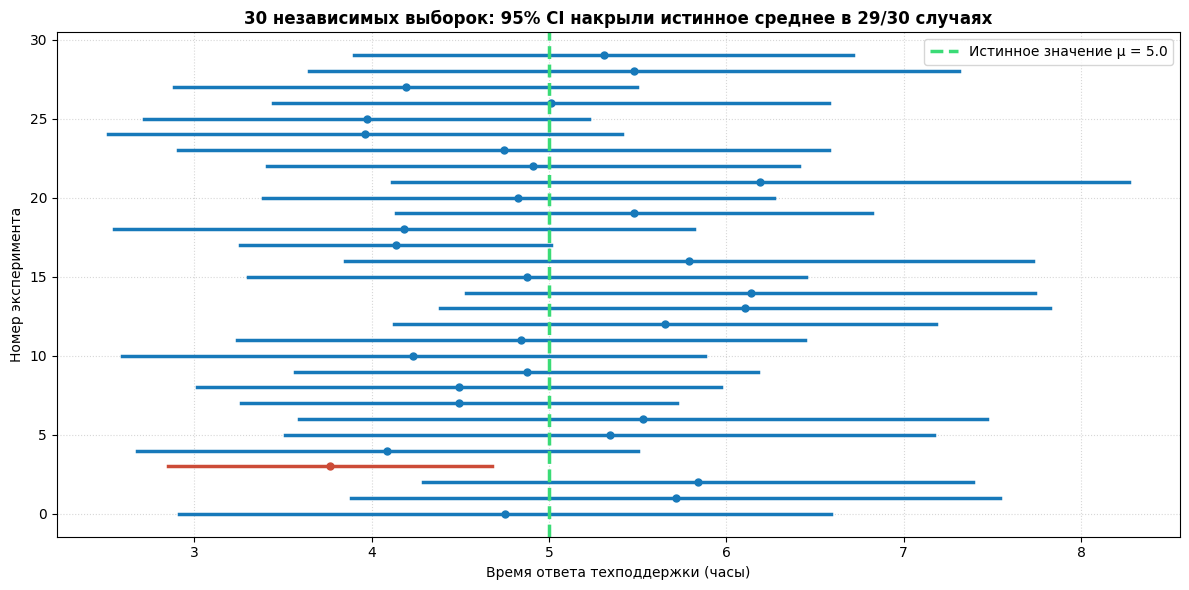

In [4]:
fig, ax = plt.subplots(figsize=(12, 6))

true_mean = 5.0
n_experiments = 30
sample_size = 40

hits, misses = 0, 0

for i in range(n_experiments):
    sample = np.random.choice(population, size=sample_size)
    s_mean = np.mean(sample)
    se = stats.sem(sample)
    ci_low, ci_high = stats.t.interval(0.95, df=sample_size-1, loc=s_mean, scale=se)
    
    covers_true = (ci_low <= true_mean <= ci_high)
    if covers_true:
        hits += 1
        color = '#1779ba'
    else:
        misses += 1
        color = '#cc4b37'
        
    ax.plot([ci_low, ci_high], [i, i], color=color, linewidth=2.5)
    ax.plot(s_mean, i, 'o', color=color, markersize=5)

ax.axvline(true_mean, color='#3adb76', linestyle='--', linewidth=2.5, label=f'Истинное значение μ = {true_mean}')
ax.set_title(f'30 независимых выборок: 95% CI накрыли истинное среднее в {hits}/{n_experiments} случаях', fontsize=12, fontweight='bold')
ax.set_xlabel('Время ответа техподдержки (часы)')
ax.set_ylabel('Номер эксперимента')
ax.legend(loc='upper right')
ax.grid(True, linestyle=':', alpha=0.5)

plt.tight_layout()
plt.show()

### 🎯 Практическое задание 1: Построение 99% доверительного интервала
Рассчитайте 99% доверительный интервал для времени ответа на выборке размера $n=100$ и сравните его ширину с 95% интервалом.

In [5]:
### ВАШ КОД ЗДЕСЬ
sample = np.random.choice(population, size=100)
mean_s = np.mean(sample)
se = stats.sem(sample)

ci_95 = stats.t.interval(0.95, df=99, loc=mean_s, scale=se)
ci_99 = stats.t.interval(0.99, df=99, loc=mean_s, scale=se)

width_95 = ci_95[1] - ci_95[0]
width_99 = ci_99[1] - ci_99[0]

print(f"95% CI ширина: {width_95:.3f}")
print(f"99% CI ширина: {width_99:.3f}")

assert width_99 > width_95, "99% доверительный интервал обязан быть шире 95%"
print("✅ Тест успешно пройден!")

95% CI ширина: 2.118
99% CI ширина: 2.803
✅ Тест успешно пройден!


### 💼 Когда использовать доверительные интервалы?
Всегда показывайте CI на графиках динамики метрик (Error Bars). Одиночная точка без доверительного интервала вводит руководство в иллюзию абсолютной точности.